# TMS lung FACS

In [ ]:
import os
import sys

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata
import scallop as sl
import triku as tk

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12

sys.path.append('../../')
from stacked_barplots import plot_stacked_bar

seed=10

composition = 'original_composition'
# composition = 'balanced_composition'

In [2]:
adata = sc.read('../../data/anndatas/annotated/TMS_facs_annotated.h5ad')

In [3]:
broad_cat = pd.read_csv('../../data/palettes/Cell_type_palette.csv', index_col=0).loc[:,'cat_broad']
cat_dic = {cat: broad_cat[broad_cat==cat].index.tolist() for cat in broad_cat}
adata.obs['cell_category'] = [broad_cat[ct] for ct in adata.obs['cell_type']]

... storing 'cell_category' as categorical


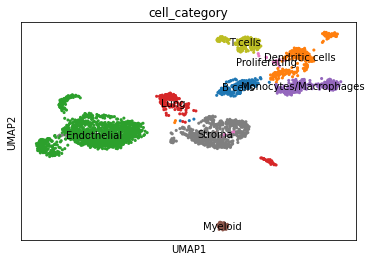

In [4]:
sc.pl.umap(adata, color='cell_category', legend_loc='on data', legend_fontsize=10, legend_fontweight=10)

In [5]:
age_dic = {'3m': 'Young', '24m': 'Old', '30m': 'Old', 'Young':'Young', 'Old': 'Old'}
adata.obs['age'] = [age_dic[age] for age in adata.obs['age']]

In [6]:
path2output = '../../data/anndatas/adatas_per_cell_cat/tms_facs/'

for cat in cat_dic:
    print(cat)
    adata_x = adata[adata.obs['cell_category'] == cat]
    # Downsampling so that the young and old have the same amount of cells
#     sel_per_cat = []
#     adata_x_young = adata_x[adata_x.obs['age'] == 'Young']
#     adata_x_old = adata_x[adata_x.obs['age'] == 'Old']
#     for ct in cat_dic[cat]:
#         n_cells = min(adata_x_young[adata_x_young.obs['cell_type']==ct].shape[0], adata_x_old[adata_x_old.obs['cell_type']==ct].shape[0])
#         sel_young = adata_x_young[adata_x_young.obs['cell_type']==ct].obs['cell_type'].sample(n_cells).index
#         sel_old = adata_x_old[adata_x_old.obs['cell_type']==ct].obs['cell_type'].sample(n_cells).index
#         sel_per_cat.extend(sel_young)
#         sel_per_cat.extend(sel_old)
#     adata_x = adata_x[adata_x.obs_names.isin(sel_per_cat)]
    cat_name = cat.replace(' ', '_')
    cat_name = cat_name.replace('/', '_')
    print(adata_x.shape)
    adata_x.write(f'{path2output}{cat_name}_{composition}.h5ad')

Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


T cells
(195, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


B cells
(220, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Endothelial
(1316, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Monocytes/Macrophages
(263, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Dendritic cells
(306, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Lung
(198, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Stroma
(571, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Myeloid
(65, 18427)


Trying to set attribute `.obs` of view, copying.
... storing 'age' as categorical


Proliferating
(20, 18427)
Megakaryocytes
(0, 18427)
Red blood cells
(0, 18427)
Others
(0, 18427)


# Run Scallop on each category - young vs old

In [7]:
def run_scallop_various_res(adata, res_vals):
    scal = sl.Scallop(adata)
    for i, res in enumerate(res_vals):
        adata.obs[f'entropy_score_{res}'] = sl.tl.getScore(scal, score_type='entropy', res=res, n_trials=30, frac_cells=0.8, do_return=True)
        adata.obs[f'freq_score_{res}'] = sl.tl.getScore(scal, score_type='freq', res=res, n_trials=30, frac_cells=0.8, do_return=True)
        adata.obs[f'leiden_{res}'] = scal.list_bootstraps[i].ident.astype(str)
    return scal

In [8]:
done_ct = ['_'.join(fname.split('_')[0:-2]) for fname in os.listdir(path2output)]
done_ct

['Proliferating',
 'Dendritic_cells',
 'T_cells',
 'Monocytes_Macrophages',
 'Endothelial',
 'B_cells',
 'Lung',
 'Others',
 'Red_blood_cells',
 'Myeloid',
 'Megakaryocytes',
 'Stroma']

In [ ]:
path2output = '../../data/anndatas/adatas_per_cell_cat_membership/tms_facs/'
path2input = '../../data/anndatas/adatas_per_cell_cat/tms_facs/'


done_ct = ['_'.join(fname.split('_')[0:-2]) for fname in os.listdir(path2output)]
res_vals = [round(i*0.1, 2) for i in range(1, 16)]

for fname in os.listdir(path2input):
    if fname.split('.h5ad')[0] not in done_ct:
        adata_ct = sc.read(f'{path2input}{fname}')
        print(f'{path2input}{fname}', adata_ct.shape[0])
        # Separate young and old cells
        adata_ct_young = adata_ct[adata_ct.obs['age'] == 'Young']
        adata_ct_old = adata_ct[adata_ct.obs['age'] == 'Old']
    
        if adata_ct_young.shape[0] > 20 and adata_ct_old.shape[0] > 20:

            # Number of cells to subsample per cell type
            
            ### Feature selection ###
            sc.pp.filter_genes(adata_ct_young, min_cells=5) # need to run this again after separating young/old
            sc.pp.filter_genes(adata_ct_old, min_cells=5)
#             tk.tl.triku(adata_ct_young)
#             tk.tl.triku(adata_ct_old)
            sc.pp.highly_variable_genes(adata_ct_young)
            sc.pp.highly_variable_genes(adata_ct_old)

            ### Principal Component Analysis ###
            sc.pp.pca(adata_ct_young)
            sc.pp.pca(adata_ct_old)
            
            ### Batch effect correction ###
#             sce.pp.harmony_integrate(adata_ct_young, key='mouse.id')
#             sce.pp.harmony_integrate(adata_ct_old, key='mouse.id')
            
#             sc.pp.neighbors(adata_ct_young, use_rep='X_pca_harmony')
#             sc.pp.neighbors(adata_ct_old, use_rep='X_pca_harmony')

            sce.pp.bbknn(adata_ct_young, batch_key='mouse.id')
            sce.pp.bbknn(adata_ct_old, batch_key='mouse.id')
            
    
            ### UMAP ###
            sc.tl.umap(adata_ct_young)
            sc.tl.umap(adata_ct_old)
            
            ### Scallop ###
            scal = run_scallop_various_res(adata_ct_young, res_vals)
            scal = run_scallop_various_res(adata_ct_old, res_vals)

            print('Running Scallop', fname)
      
            ct = fname.split('.')[0]
            adata_ct_young.write(f'{path2output}{ct}_young_membership.h5ad')
            adata_ct_old.write(f'{path2output}{ct}_old_membership.h5ad')

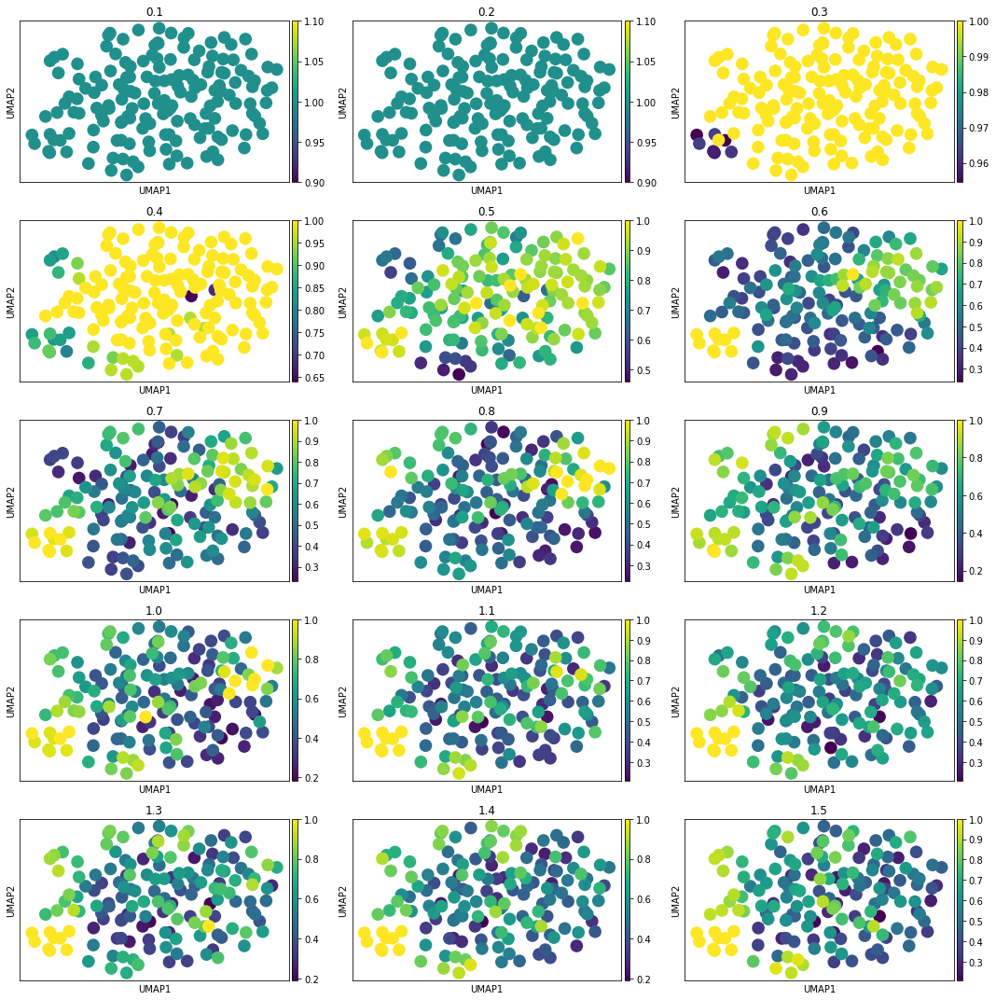

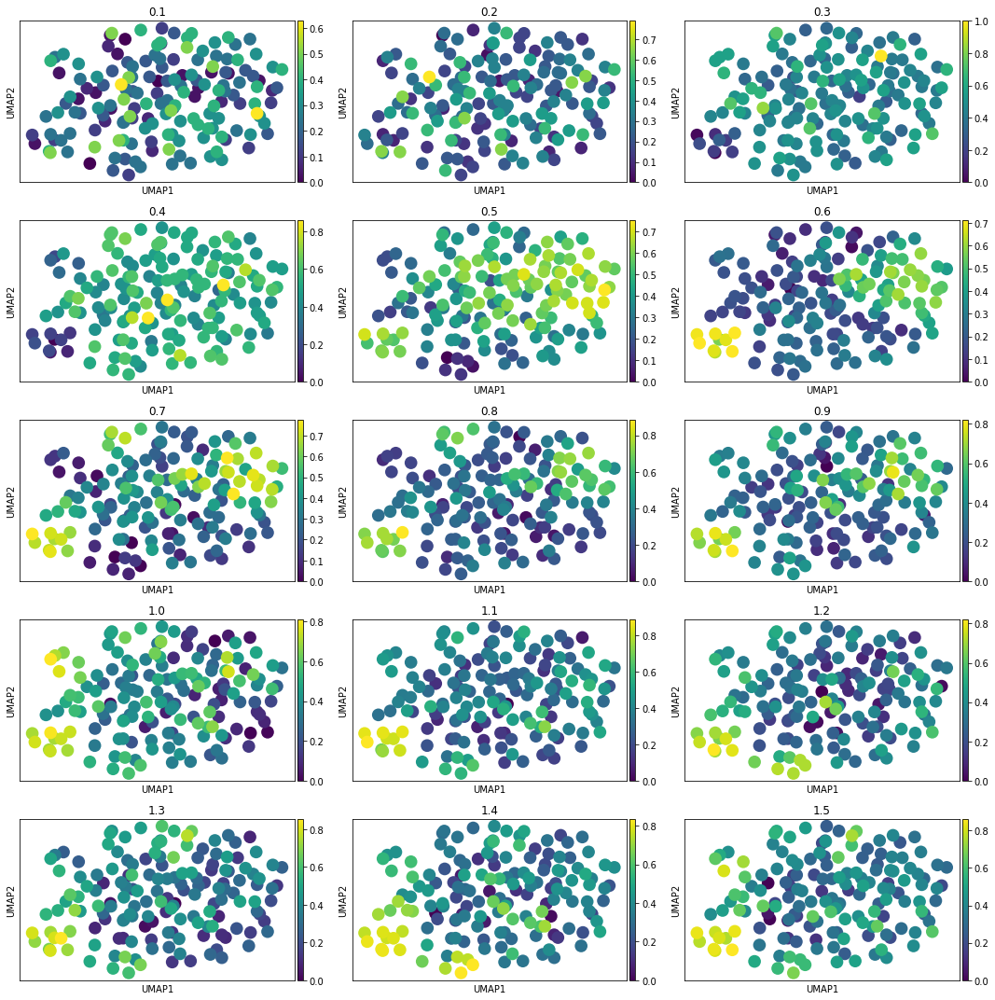

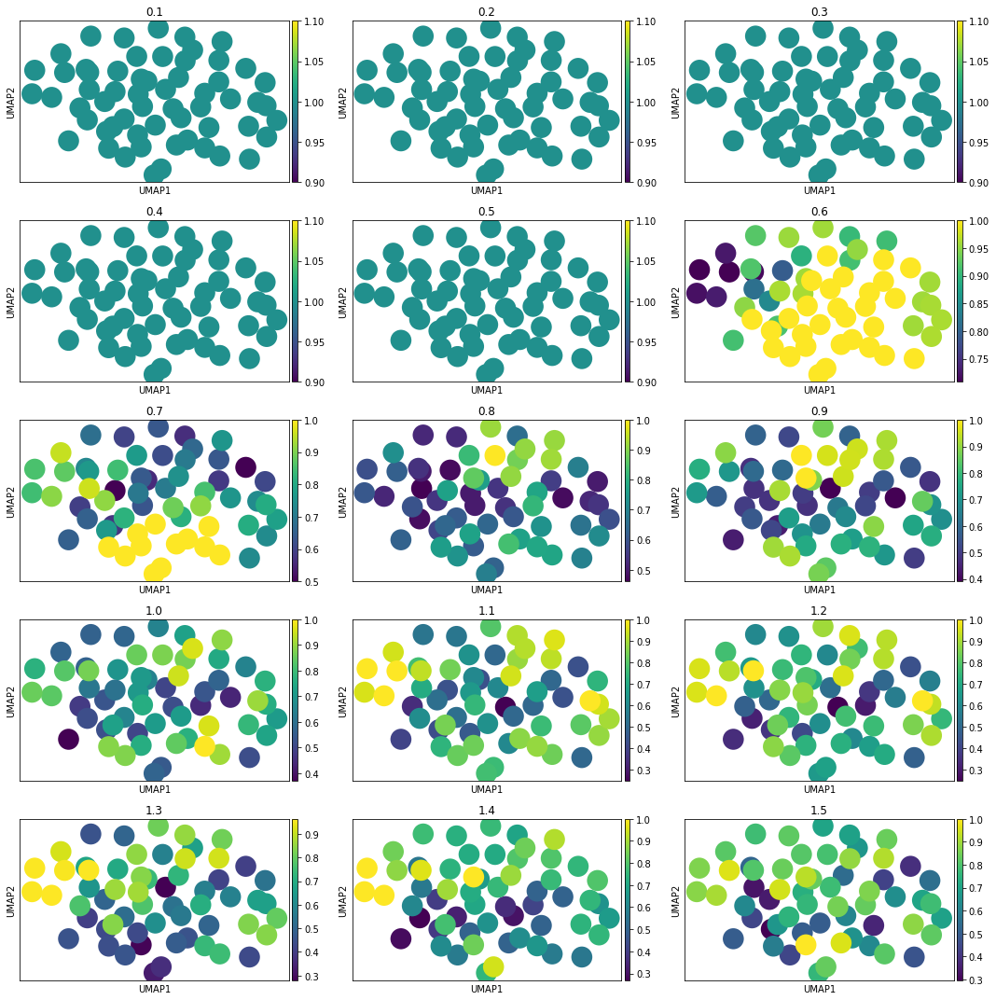

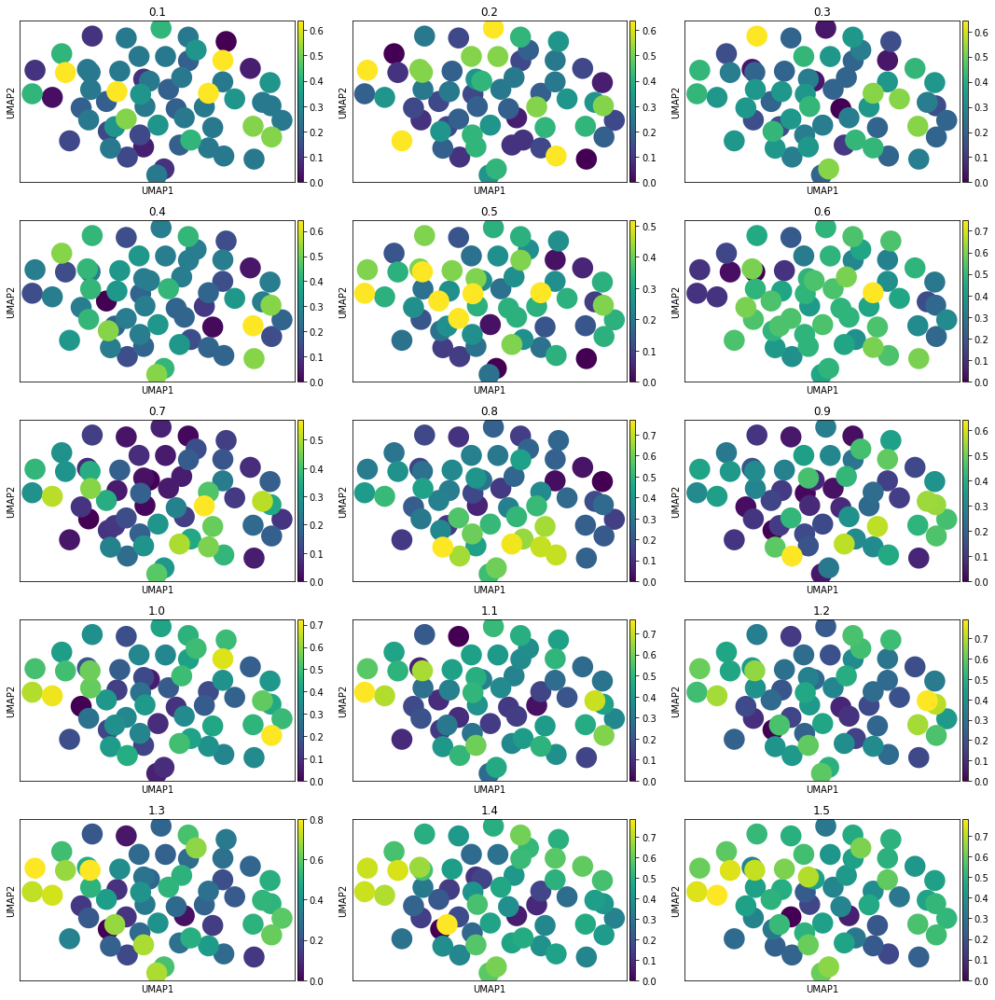

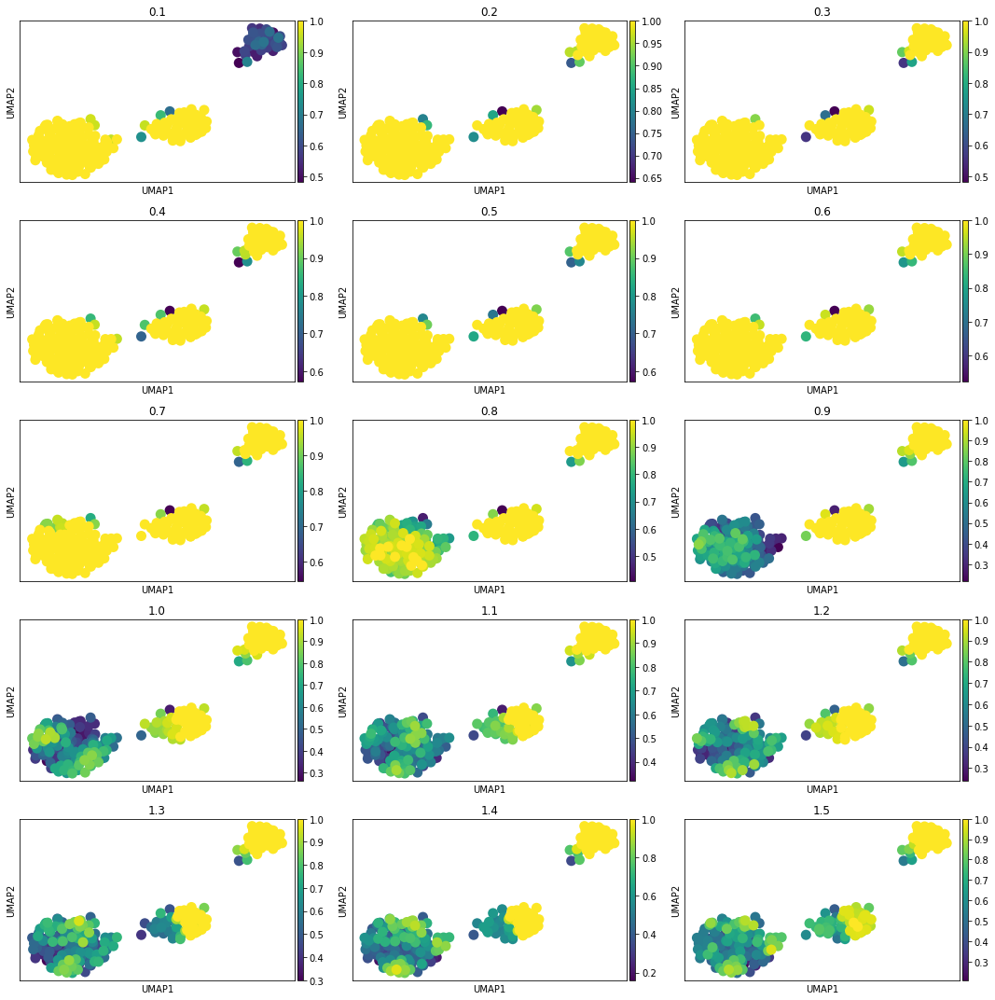

...

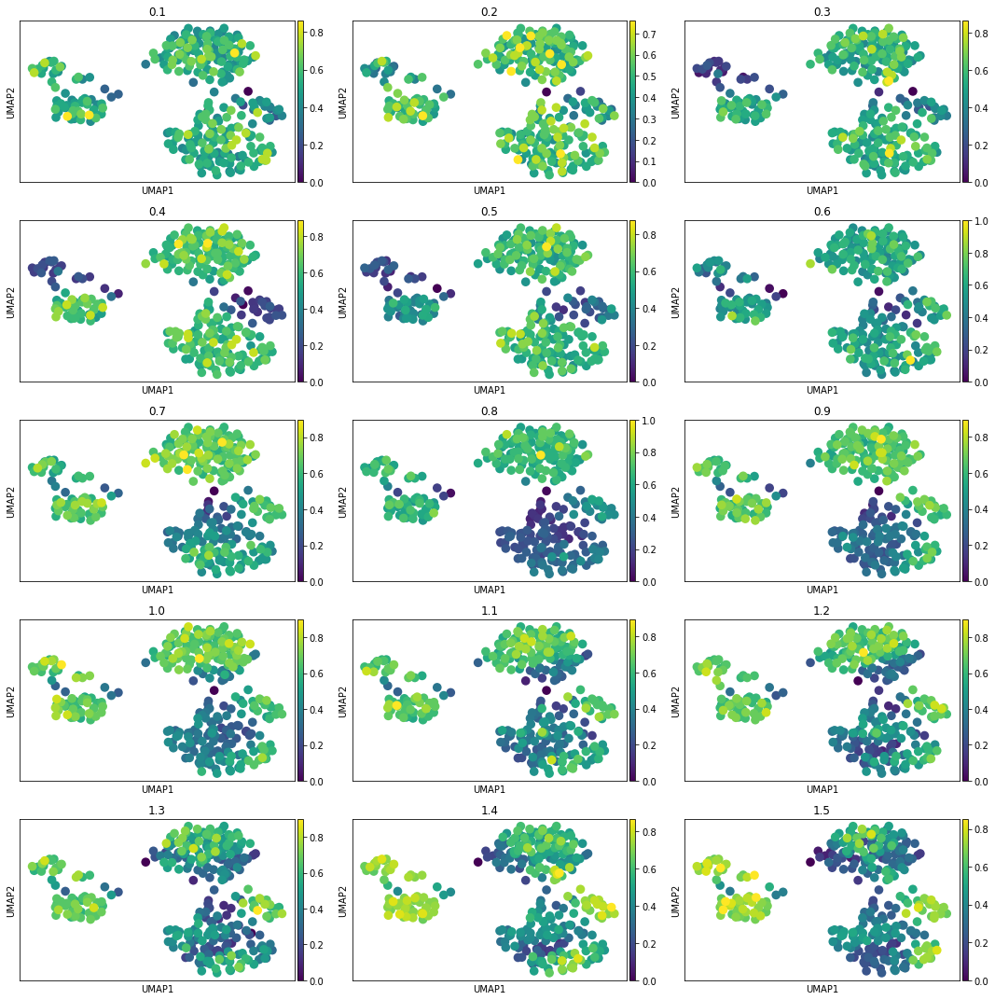

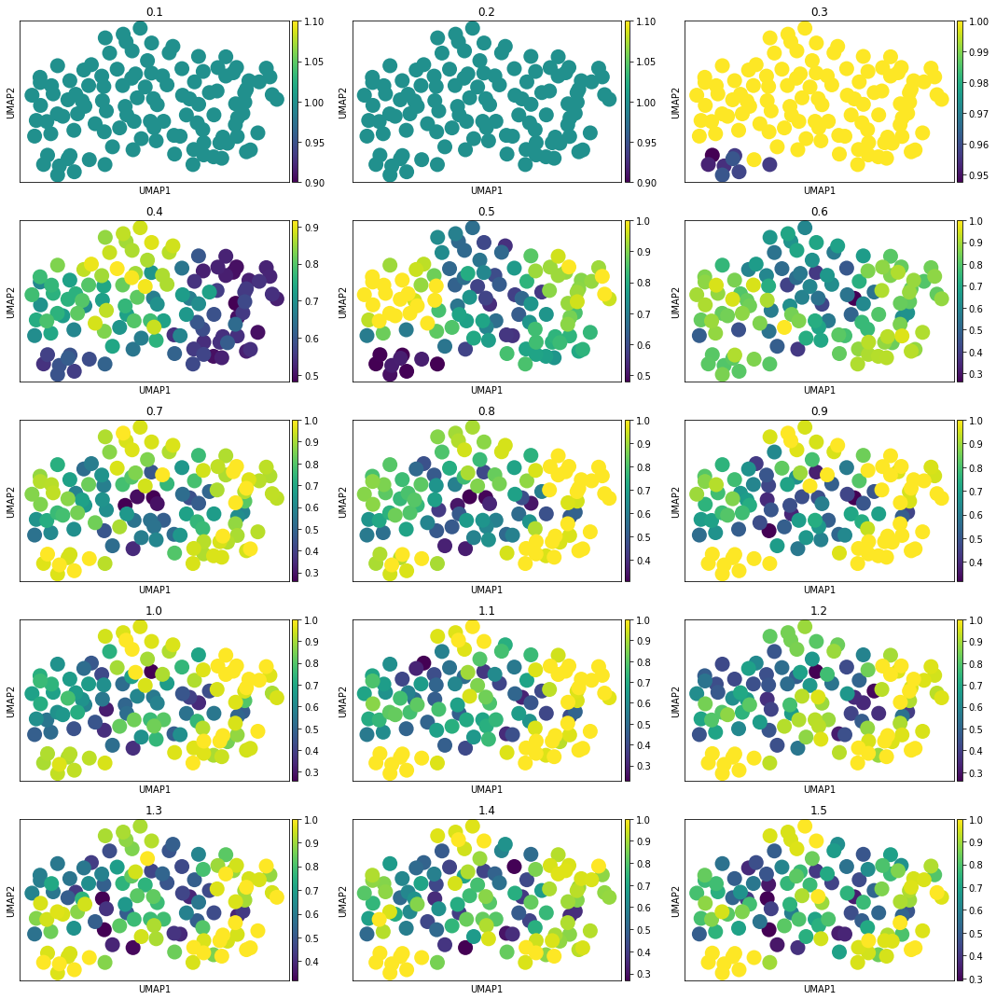

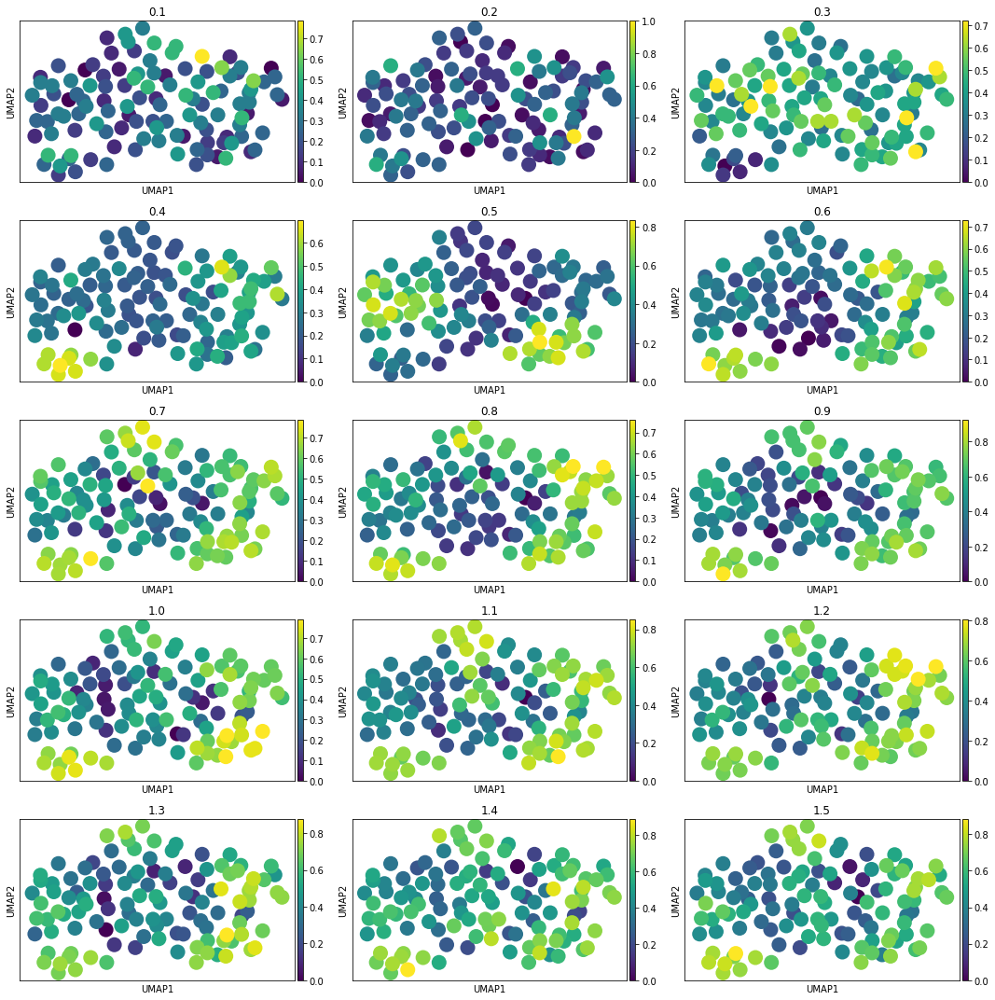

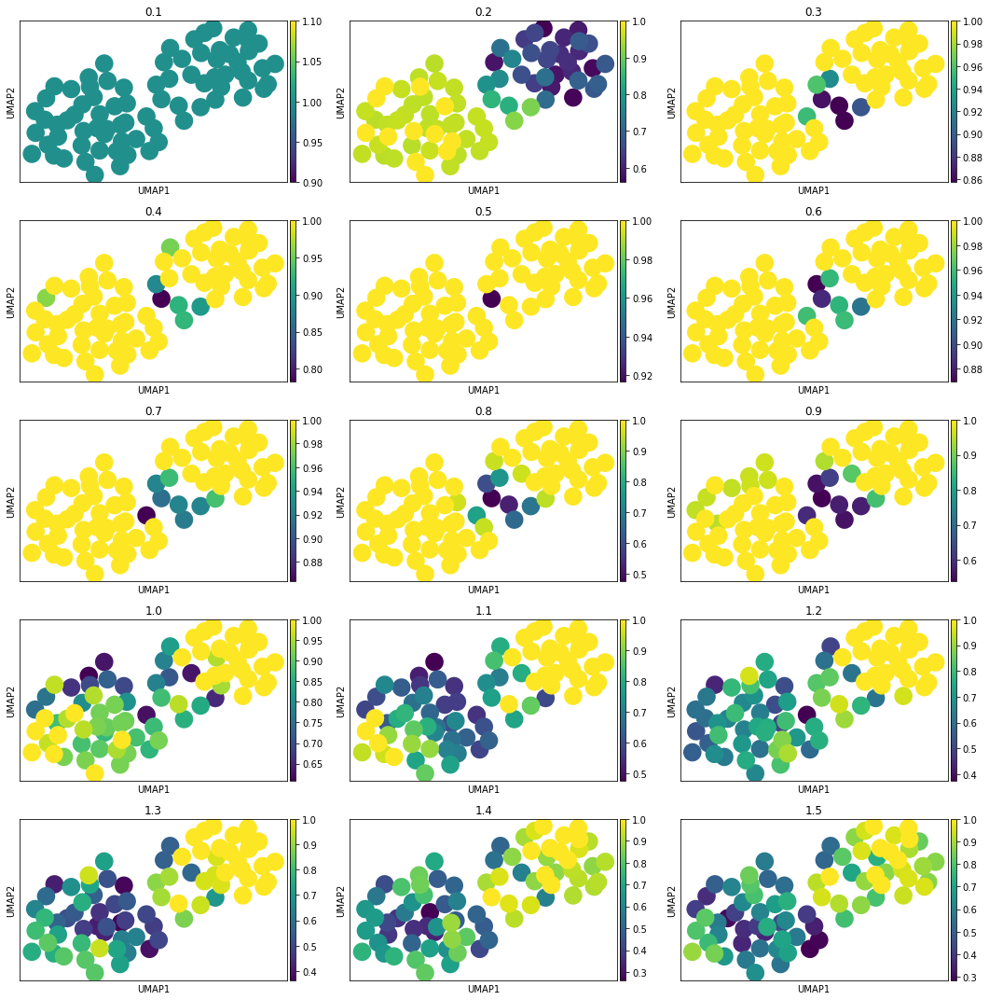

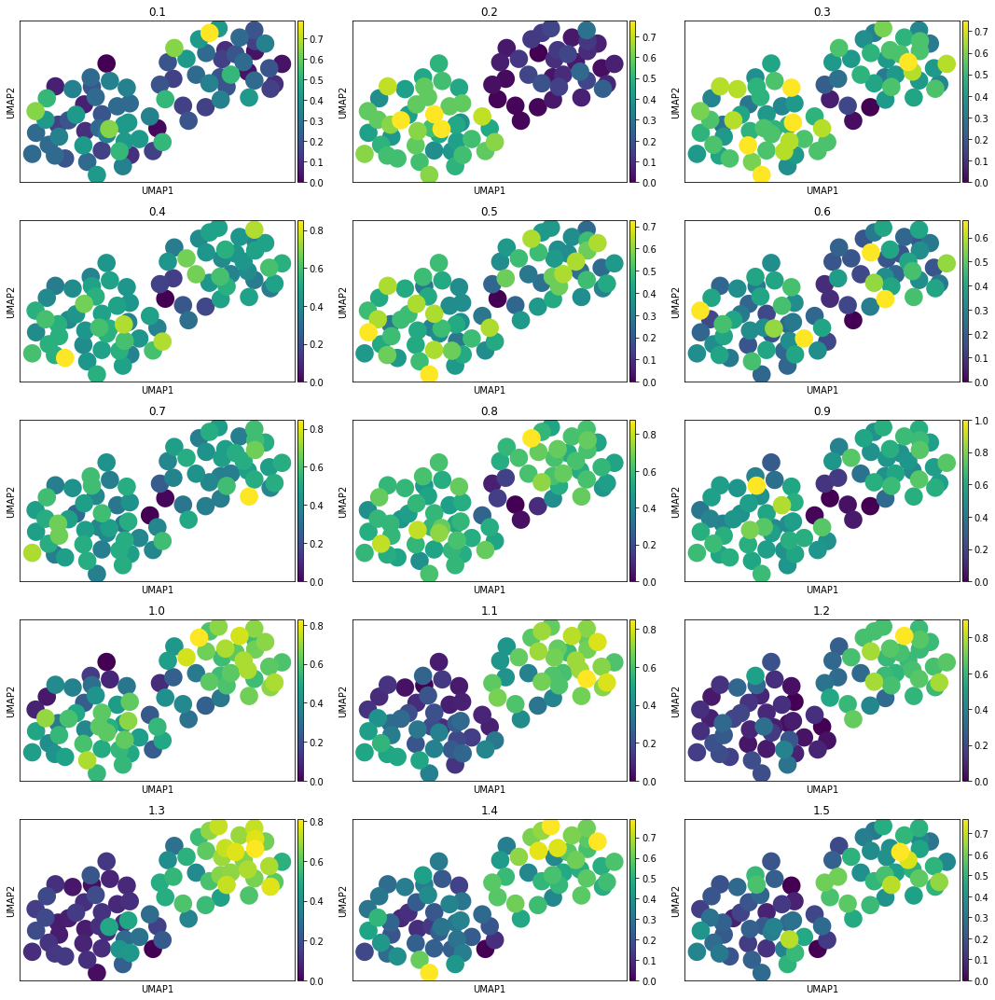

In [13]:
path2input = '../../data/anndatas/adatas_per_cell_cat_membership/tms_facs/'
path2output= '../../output/umaps/membership/tms_facs/'
res_vals = [round(i*0.1, 2) for i in range(1, 16)]
for fname in [fname for fname in sorted(os.listdir(path2input)) if fname.endswith('h5ad')]:
    adata_x = sc.read(f'{path2input}{fname}')
    res_arr = np.reshape(res_vals, (5, 3))
    nrows, ncols = res_arr.shape
    for score_type in ['freq', 'entropy']:
        fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*3))
        for i in range(nrows):
            for j in range(ncols):
                res = res_arr[i][j]
                sc.pl.umap(adata_x, color=f'{score_type}_score_{res}', ax=axs[i][j], show=False)
                axs[i][j].set_title(res)
        plt.tight_layout()
        ct = fname.split('.h5ad')[0]
        plt.savefig(f'{path2output}{ct}_{score_type}.png')

# Plot annotations

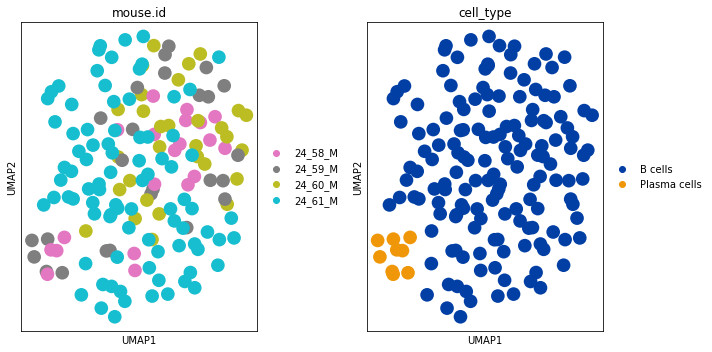

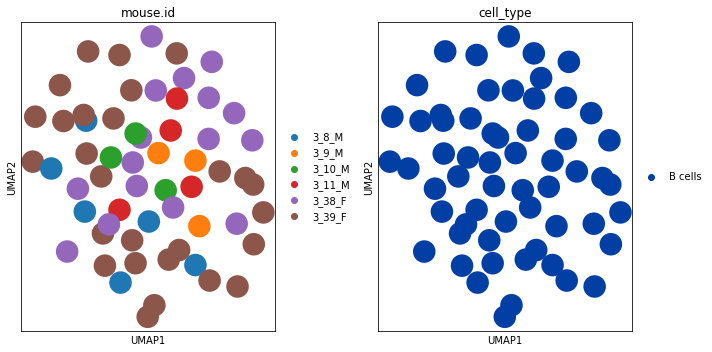

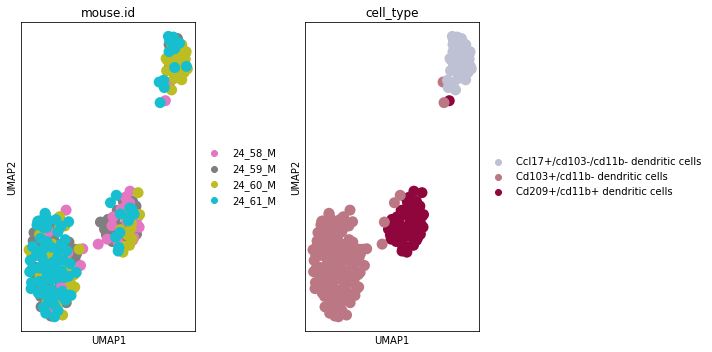

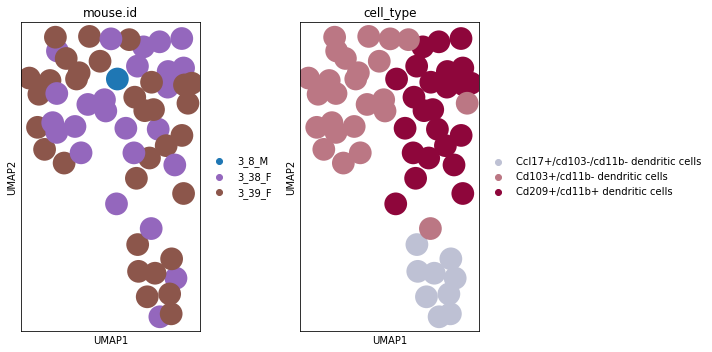

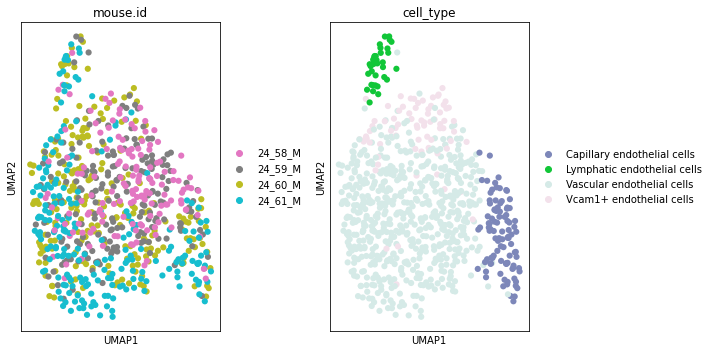

...

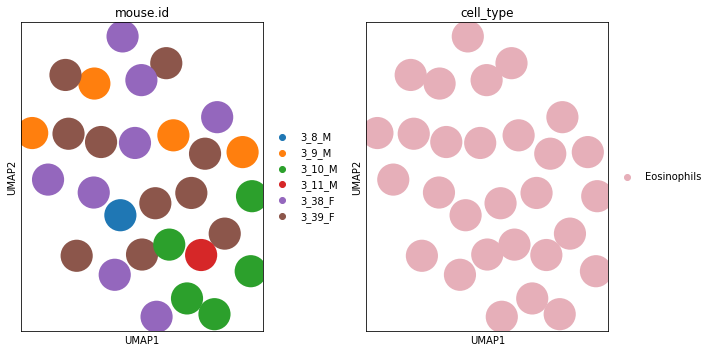

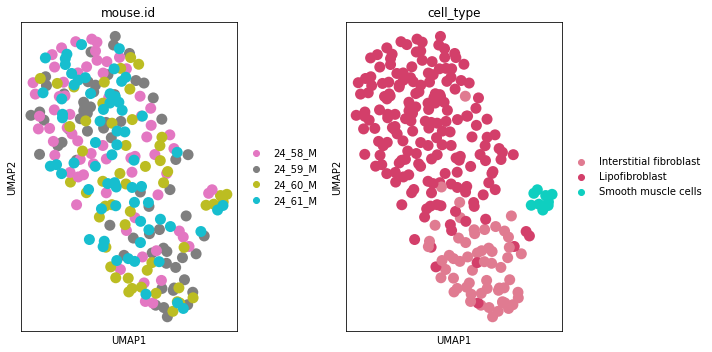

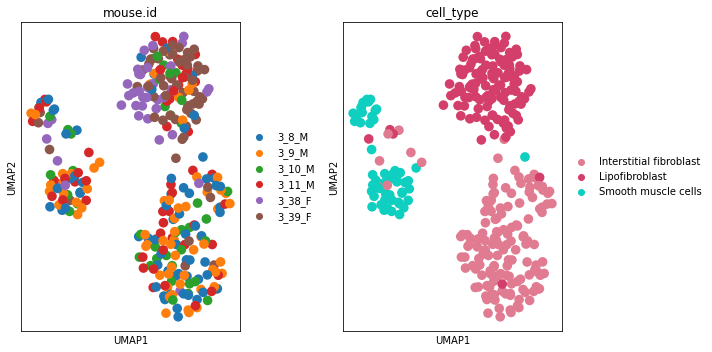

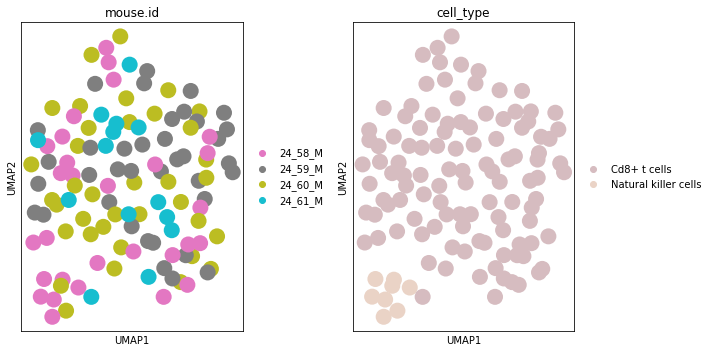

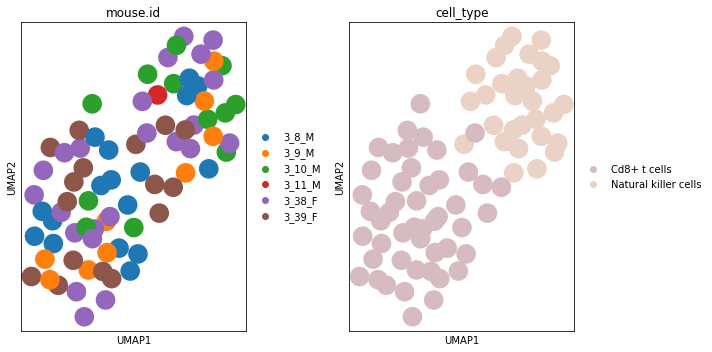

In [15]:
path2input = '../../data/anndatas/adatas_per_cell_cat_membership/tms_facs/'
path2output= '../../output/umaps/annotation/tms_facs/'

for fname in [fname for fname in sorted(os.listdir(path2input)) if fname.endswith('h5ad')]:
    adata_x = sc.read(f'{path2input}{fname}')
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
    sc.pl.umap(adata_x, color='mouse.id', ax=axs[0], show=False)
    sc.pl.umap(adata_x, color='cell_type', ax=axs[1], show=False)

    plt.tight_layout()
    ct = fname.split('.h5ad')[0]
    plt.savefig(f'{path2output}{ct}.png')

In [26]:
path2input = '../../data/anndatas/adatas_per_cell_cat_membership/tms_facs/'
path2output = '../../output/tables/membership_dataframes/tms_facs/'

cell_cats =  list(set(['_'.join(fname.split('_')[0:-2]) for fname in os.listdir(path2input) if fname.endswith('h5ad')]))

res_vals = [round(i*0.1, 2) for i in range(4, 16)]
for cat in cell_cats:
    adata_young = sc.read(f'{path2input}{cat}_young_membership.h5ad')
    adata_old = sc.read(f'{path2input}{cat}_old_membership.h5ad')
    
    # Compute the mean membership score for both score types (frequency and entropy) in the two
    # age groups (young and old). The mean membership scores will be saved in two dictionaries
    # (memberships_freq and memberships_entropy). 
    ages = ['young', 'old']
    memberships_freq = dict()
    memberships_entropy = dict()
    for age in ages: 
        adata_x = eval(f'adata_{age}')
        memberships_freq[age] = np.mean(adata_x.obs[[f'freq_score_{res}' for res in res_vals]], axis=1)
        memberships_entropy[age] = np.mean(adata_x.obs[[f'entropy_score_{res}' for res in res_vals]], axis=1)
    
    # We create a dataframe with the mean membership scores of all 
    all_cells = list(memberships_freq['young'].index.tolist() + memberships_freq['old'].index.tolist())
    
    distributions_freq = pd.DataFrame(index = all_cells)
    distributions_entropy = pd.DataFrame(index = all_cells)
    for score_type in ['freq', 'entropy']:
        df = eval(f'distributions_{score_type}')
        membership_dict = eval(f'memberships_{score_type}')
        for age in ages:
            adata_x = eval(f'adata_{age}')
            m = membership_dict[age]
            df.loc[m.index, 'mean_membership'] = m.values
            df.loc[m.index, 'age'] = adata_x.obs['age']
            df.loc[m.index, 'cell_type'] = adata_x.obs['cell_type']
        df.to_csv(f'{path2output}Distributions_membership_{cat}_{score_type}.csv')

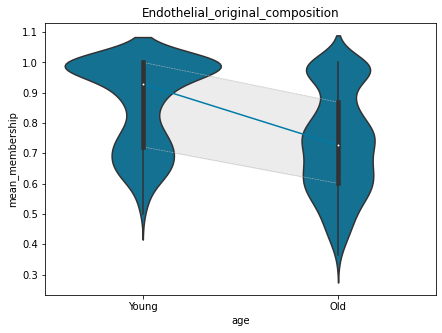

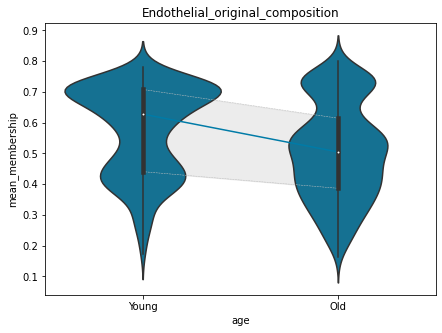

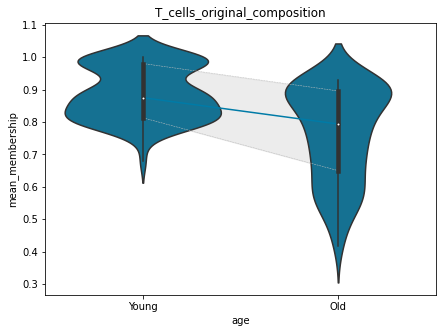

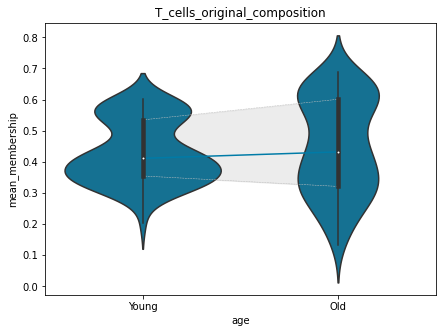

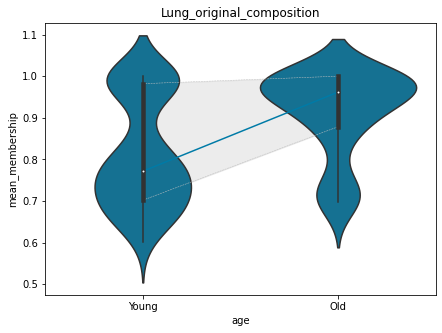

...

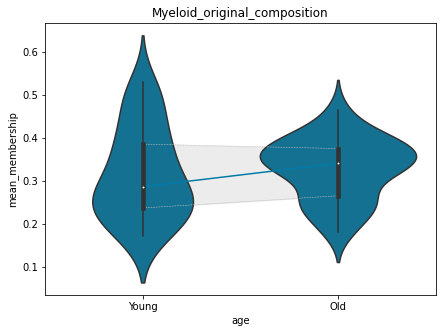

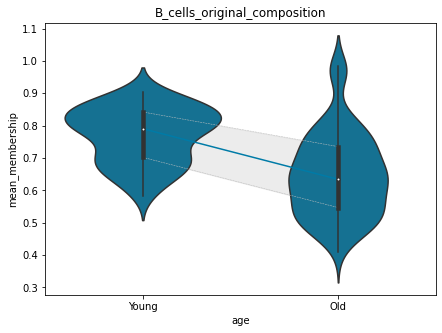

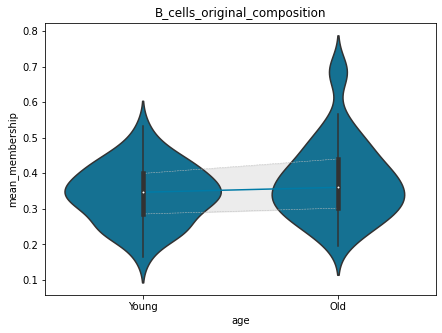

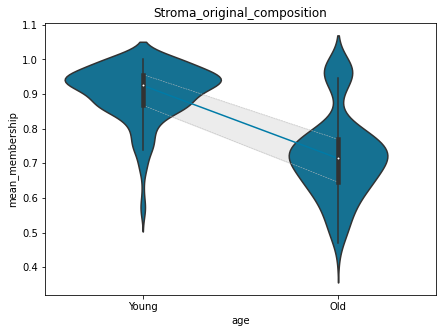

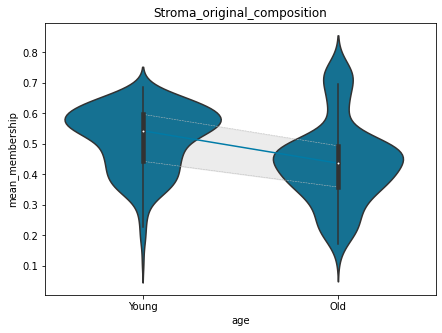

In [27]:
path2input = '../../output/tables/membership_dataframes/tms_facs/'
path2output = '../../output/figs/violins_age/tms_facs/'

for cat in cell_cats:
    for score_type in ['freq', 'entropy']:
        df = pd.read_csv(f'{path2input}Distributions_membership_{cat}_{score_type}.csv')
        # Compute median, mean, and quartiles:
        median, mean, q25, q75 = [], [], [], []
        ages = ['Young', 'Old']
        for age in ages:
            median.append(np.median(df[df.age==age].mean_membership))
            mean.append(np.mean(df[df.age==age].mean_membership))
            q25.append(np.quantile(df[df.age==age].mean_membership, 0.25))
            q75.append(np.quantile(df[df.age==age].mean_membership, 0.75))

        fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
        ax.plot(ages, q25, '--', color='#C1C1C1', linewidth=0.5)
        ax.plot(ages, q75, '--', color='#C1C1C1', linewidth=0.5)
        ax.fill_between(ages, q25, q75, alpha=0.3, color='#C1C1C1')
        ax.plot(ages, median, color='#007BA7')
        sns.violinplot(data = df, x= 'age', y='mean_membership', order=ages, ax=ax, color='#007BA7', jitter=0.25, alpha=0.6)
        ax.set_title(cat)
        plt.savefig(f'{path2output}{cat}_{score_type}_freq_age-groups.png')


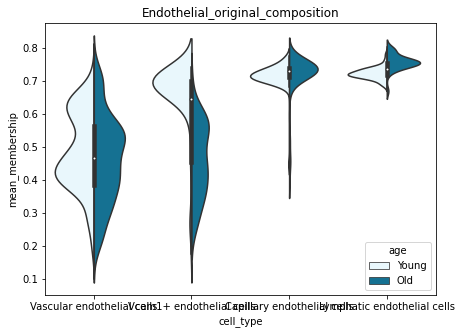

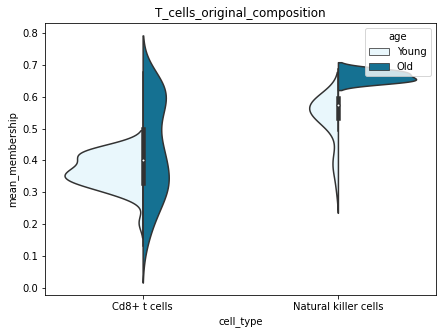

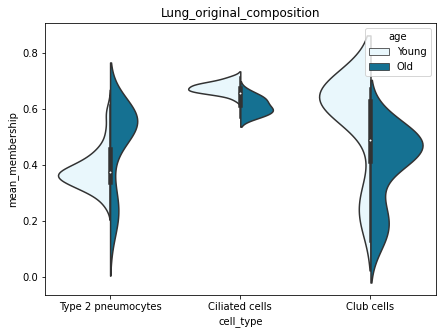

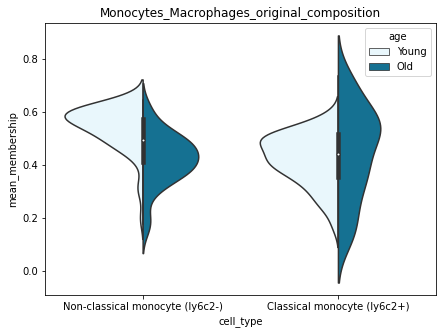

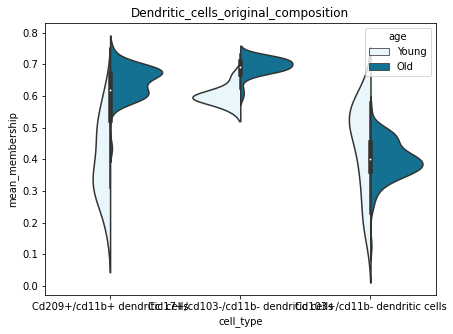

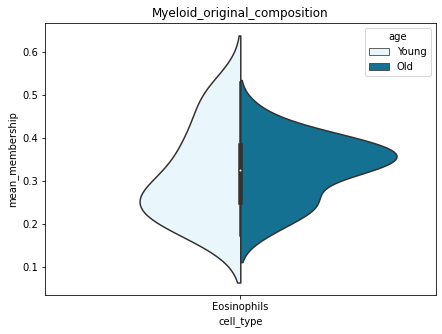

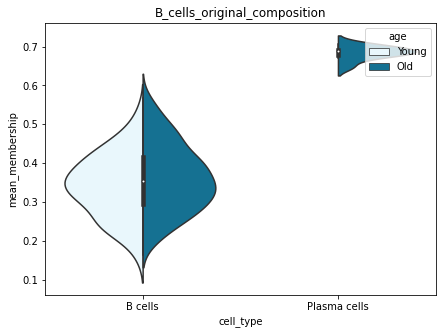

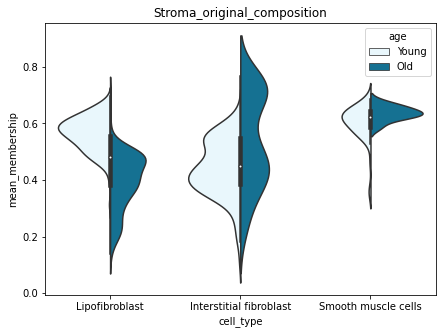

In [28]:
path2input = '../../output/tables/membership_dataframes/tms_facs/'
path2output = '../../output/figs/violins_age_ct/tms_facs/'


for cat in cell_cats:
    for score_type in ['freq', 'entropy']:
        try:
            df = pd.read_csv(f'{path2input}Distributions_membership_{cat}_{score_type}.csv')
        except:
            pass
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
    sns.violinplot(data = df, x= 'cell_type', hue='age', split=True, y='mean_membership', ax=ax, color='#007BA7', s=0.5, jitter=0.25, alpha=0.6)
    ax.set_title(cat)
    plt.savefig(f'{path2output}{cat}_{score_type}_freq_age-groups_per_ct.png')

In [29]:
df = pd.DataFrame()
path2input = '../../output/tables/membership_dataframes/tms_facs/'
for fname in os.listdir(path2input):
    if fname.endswith('_freq.csv'):
        print(fname)
        new_df = pd.read_csv(path2input + fname)
        df = pd.concat([df, new_df])

Distributions_membership_B_cells_original_composition_freq.csv
Distributions_membership_Lung_original_composition_freq.csv
Distributions_membership_Endothelial_original_composition_freq.csv
Distributions_membership_T_cells_original_composition_freq.csv
Distributions_membership_Myeloid_original_composition_freq.csv
Distributions_membership_Stroma_original_composition_freq.csv
Distributions_membership_Dendritic_cells_original_composition_freq.csv
Distributions_membership_Monocytes_Macrophages_original_composition_freq.csv


In [30]:
df.to_csv(f'../../output/tables/membership_dataframes/TMS_facs_{composition}_memberships.csv')